In [1]:
%cd D:/ML/Assignment

D:\ML\Assignment


In [ ]:
# Machine Learning Assignment
## Clustering Algorithms on Iris Dataset

### Objective:
To apply unsupervised machine learning clustering algorithms
to the Iris dataset.

In [14]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

In [15]:
# Load Iris dataset
DATA_PATH = "D:/ML/Assignment/iris.csv.csv"

df = pd.read_csv(DATA_PATH)

display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,class
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [17]:
# Check data
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Shape: (150, 6)

Columns:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target', 'class']

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
class                0
dtype: int64


In [18]:
# Check the classes

print("Class distribution:")
print(df["class"].value_counts())

Class distribution:
class
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [20]:
# Select features
X = df.drop(["target", "class"], axis=1)

print("Features used for clustering:")
display(X.head())

Features used for clustering:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [21]:
# Standardize data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data:")
print(X_scaled[:5])

Scaled data:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [22]:
# 1. K-Means clustering

kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means cluster labels:")
print(kmeans_labels)

K-Means cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [23]:
# Cluster sizes
unique, counts = np.unique(kmeans_labels, return_counts=True)

print("K-Means cluster sizes:")

for cluster, count in zip(unique, counts):
    print("Cluster", cluster, ":", count, "samples")

K-Means cluster sizes:
Cluster 0 : 53 samples
Cluster 1 : 50 samples
Cluster 2 : 47 samples


In [24]:
#PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original dimensions:", X_scaled.shape)
print("PCA dimensions:", X_pca.shape)

Original dimensions: (150, 4)
PCA dimensions: (150, 2)


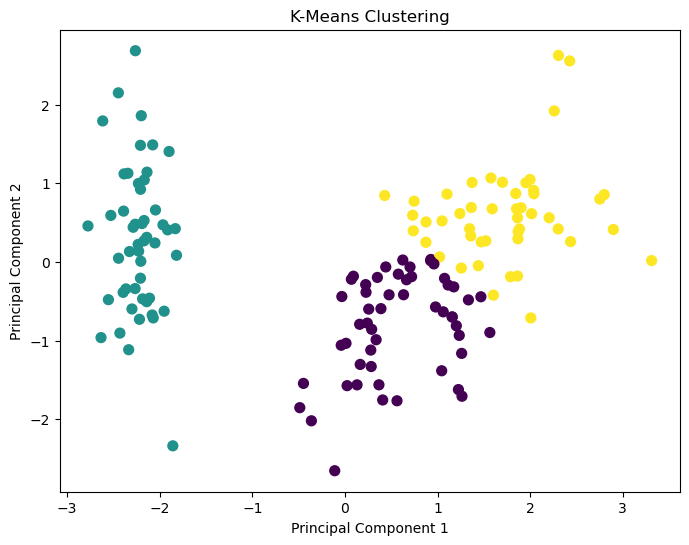

In [25]:
#Visualize K-Means
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering")

plt.show()

In [26]:
# 2. Hierarchical clustering
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    metric="euclidean",
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Hierarchical cluster labels:")
print(hierarchical_labels)

Hierarchical cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


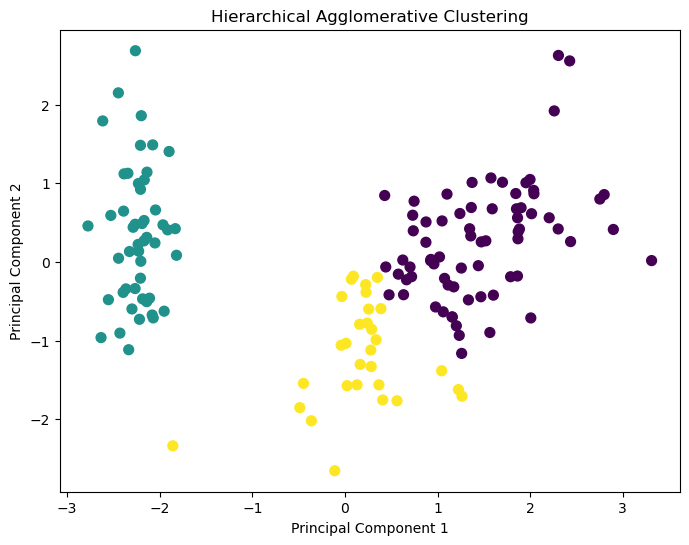

In [27]:
#Visualize hierarchical clustering
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Hierarchical Agglomerative Clustering")

plt.show()

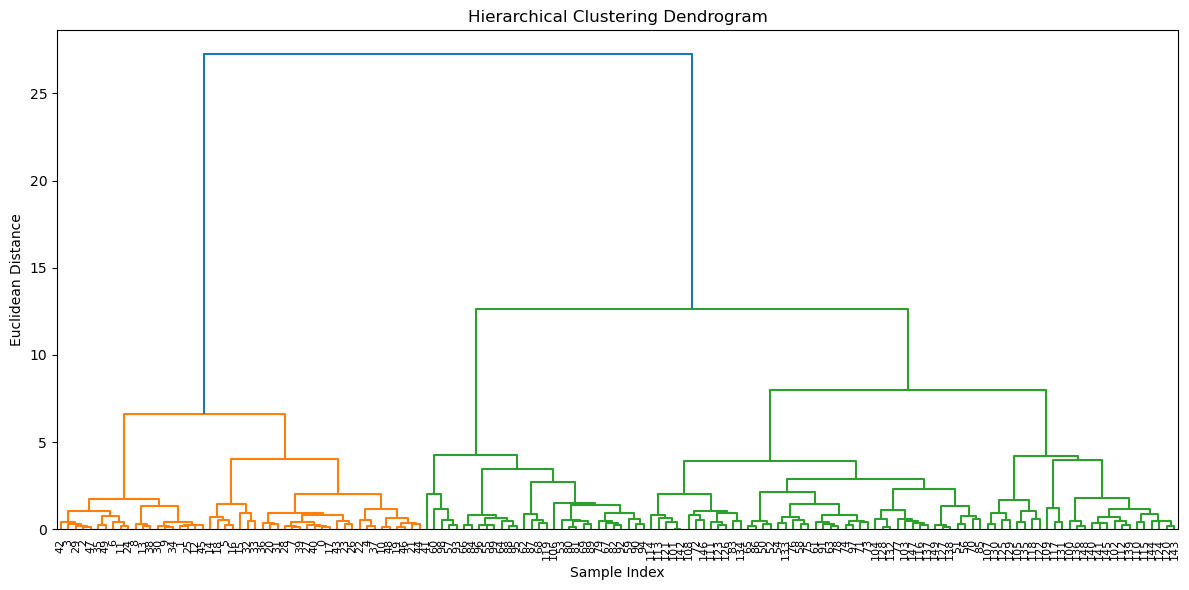

In [28]:
# 3. Dendrogram
linked = linkage(
    X_scaled,
    method="ward"
)

plt.figure(figsize=(12, 6))

dendrogram(
    linked,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distance")

plt.tight_layout()
plt.show()

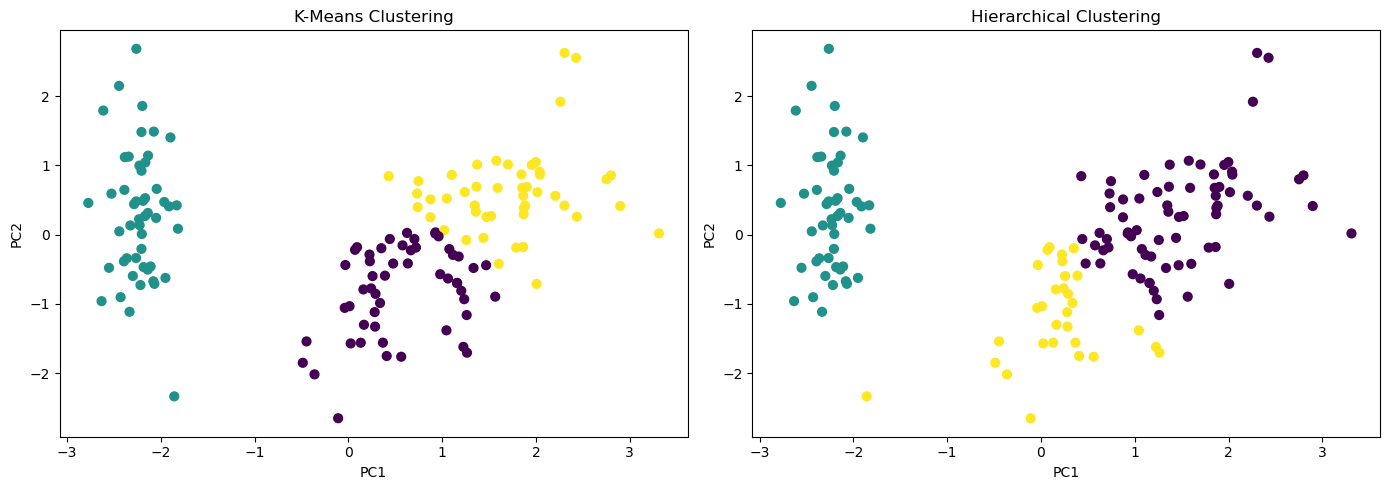

In [29]:
#Compare clustering algorithms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-Means
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    s=40
)

axes[0].set_title("K-Means Clustering")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")


# Hierarchical
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    s=40
)

axes[1].set_title("Hierarchical Clustering")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

In [ ]:
## Conclusion

Two unsupervised machine learning algorithms were applied to the
Iris dataset:

1. K-Means Clustering
2. Hierarchical Agglomerative Clustering

The four numerical features of the Iris dataset were standardized
before clustering. K-Means clustering was performed using three
clusters. Hierarchical Agglomerative Clustering was also performed
using three clusters, Euclidean distance, and Ward linkage.

PCA was used to reduce the four-dimensional feature space to two
principal components for visualization.

The clustering results were visualized using scatter plots, and a
dendrogram was generated to show the hierarchical relationships
among the samples.